In [1]:
import math
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import pprint 
pp = pprint.PrettyPrinter(indent = 2)

seed = 42

# Config the matlotlib backend as plotting inline in IPython
%matplotlib inline

In [2]:
data = pd.read_hdf('banking.h5', 'data')
target = "y"
display(data.head(10))

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,0
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,0
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,...,3,6,2,success,-1.7,94.055,-39.8,0.729,4991.6,1
3,39,services,married,high.school,no,no,no,cellular,apr,fri,...,2,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,0
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,...,1,3,1,success,-2.9,92.201,-31.4,0.869,5076.2,1
5,30,management,divorced,basic.4y,no,yes,no,cellular,jul,tue,...,8,999,0,nonexistent,1.4,93.918,-42.7,4.961,5228.1,0
6,37,blue-collar,married,basic.4y,no,yes,no,cellular,may,thu,...,1,999,0,nonexistent,-1.8,92.893,-46.2,1.327,5099.1,0
7,39,blue-collar,divorced,basic.9y,no,yes,no,cellular,may,fri,...,1,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,0
8,36,admin.,married,university.degree,no,no,no,cellular,jun,mon,...,1,3,1,success,-2.9,92.963,-40.8,1.266,5076.2,1
9,27,blue-collar,single,basic.4y,no,yes,no,cellular,apr,thu,...,2,999,1,failure,-1.8,93.075,-47.1,1.410,5099.1,0


In [3]:
from scoring_tools import calculate_woe, woe_table_to_dict

df_woe = calculate_woe(data, "job", target)
display(df_woe)

woe_dict = woe_table_to_dict(df_woe)
pp.pprint(woe_dict)

,Name,Category,Count,Events,Bad_Rate,Non-Events,Event_Distribution,Non-Event_Distribution,WoE,IV
0,job,student,875,275,0.314286,600,0.059267,0.016417,-1.283754,5.500945e-02
1,job,retired,1720,434,0.252326,1286,0.093534,0.035187,-0.977665,5.704466e-02
2,job,unemployed,1014,144,0.142012,870,0.031034,0.023804,-0.265232,1.917674e-03
3,job,admin.,10422,1352,0.129726,9070,0.291379,0.248167,-0.160525,6.936681e-03
4,job,management,2924,328,0.112175,2596,0.070690,0.071030,0.004801,1.633538e-06
5,job,unknown,330,37,0.112121,293,0.007974,0.008017,0.005343,2.282177e-07
6,job,technician,6743,730,0.108260,6013,0.157328,0.164523,0.044722,3.218128e-04
7,job,self-employed,1421,149,0.104856,1272,0.032112,0.034804,0.080487,2.166298e-04
8,job,housemaid,1060,106,0.100000,954,0.022845,0.026103,0.133312,4.343096e-04
9,job,entrepreneur,1456,124,0.085165,1332,0.026724,0.036445,0.310243,3.015900e-03


{ 'admin.': -0.16052481239193747,
  'blue-collar': 0.5391258365932243,
  'entrepreneur': 0.3102431865970874,
  'housemaid': 0.13331247843800917,
  'management': 0.004801370541626522,
  'retired': -0.9776647282010504,
  'self-employed': 0.080487339056398,
  'services': 0.3598215331177416,
  'student': -1.2837535413486352,
  'technician': 0.044722437998921664,
  'unemployed': -0.2652321868255814,
  'unknown': 0.005342597474632559}


In [4]:
df_woe = calculate_woe(data, "pdays", target)
display(df_woe.head(10))

,Name,Category,Count,Events,Bad_Rate,Non-Events,Event_Distribution,Non-Event_Distribution,WoE,IV
0,pdays,27,1,1,1.000000,0,0.000216,2.736128e-07,-6.669082,0.001435
1,pdays,26,1,1,1.000000,0,0.000216,2.736128e-07,-6.669082,0.001435
2,pdays,25,1,1,1.000000,0,0.000216,2.736128e-07,-6.669082,0.001435
3,pdays,21,2,2,1.000000,0,0.000431,2.736128e-07,-7.362229,0.003171
4,pdays,13,36,28,0.777778,8,0.006034,2.188902e-04,-3.316675,0.019288
5,pdays,6,412,289,0.701456,123,0.062284,3.365437e-03,-2.918154,0.171935
6,pdays,3,439,298,0.678815,141,0.064224,3.857940e-03,-2.812246,0.169765
7,pdays,15,24,16,0.666667,8,0.003448,2.188902e-04,-2.757059,0.008904
8,pdays,22,3,2,0.666667,1,0.000431,2.736128e-05,-2.757059,0.001113
9,pdays,0,15,10,0.666667,5,0.002155,1.368064e-04,-2.757059,0.005565


In [5]:
from scoring_tools import correlation_matrix_plot, vcramer_corr_matrix_plot

numeric_cols = data.drop([target, 'default', 'nr_employed'], axis=1).select_dtypes(include='number').columns.tolist()
string_cols = data.drop([target, 'default', 'nr_employed'], axis=1).select_dtypes(include='object').columns.tolist()

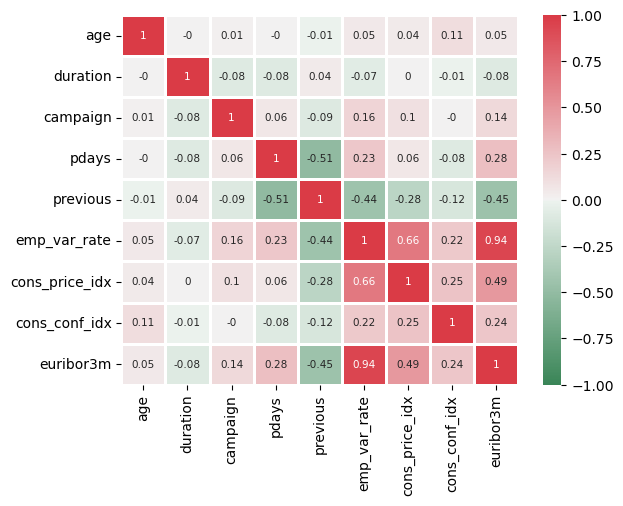

In [6]:
correlation_matrix_plot(data, numeric_cols)

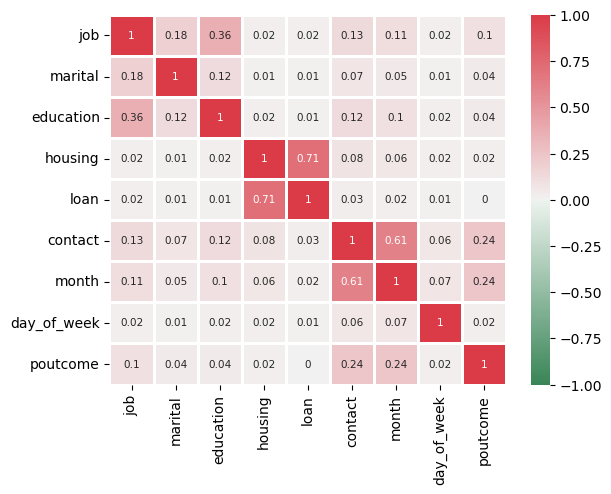

In [7]:
vcramer_corr_matrix_plot(data, string_cols)

In [8]:
from sklearn.model_selection import train_test_split

X = data.drop(columns = [target, 'default', 'nr_employed'])
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3,
    stratify=y,
    random_state=seed
)

n = len(data)
n_train = len(X_train)
n_test = len(X_test)
print(f"Train: {n_train} ({n_train/n:.4f})")
print(f"Test: {n_test} ({n_test/n:.4f})")

Train: 28831 (0.7000)
Test: 12357 (0.3000)


In [9]:
from scoring_tools import calculate_psi, plot_psi

psi_records = []
for col in numeric_cols:
    psi_val = calculate_psi(X_train[col], X_test[col])
    psi_records.append({'Feature': col, 'PSI': psi_val})

psi_df = pd.DataFrame(psi_records)

def interpret_psi(psi):
    if psi < 0.10:
        return 'Stable'
    elif psi < 0.25:
        return 'Moderate Shift'
    else:
        return 'Significant Shift'

psi_df['Stability_Status'] = psi_df['PSI'].apply(interpret_psi)

print("Population Stability Index:")
display(psi_df)

Population Stability Index:


,Feature,PSI,Stability_Status
0,age,0.000701,Stable
1,duration,0.000582,Stable
2,campaign,0.000649,Stable
3,pdays,0.000000,Stable
4,previous,0.000167,Stable
5,emp_var_rate,0.000143,Stable
6,cons_price_idx,0.000553,Stable
7,cons_conf_idx,0.000474,Stable
8,euribor3m,0.000640,Stable


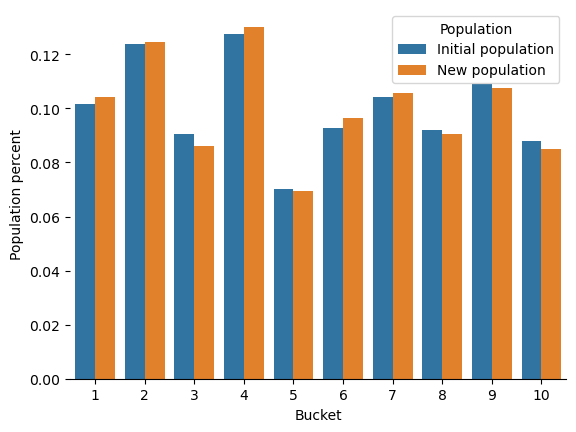

In [10]:
col = 'age'
col_str = 'housing'

plot_psi(X_train[col], X_test[col])

In [11]:
from scoring_tools import fine_classing_numeric, fine_classing_string, coarse_classing_numeric, coarse_classing_string

df_train = X_train
df_train[target] = y_train

df_fc = fine_classing_numeric(df_train, col, null_separate = True)
display(df_fc)

df_fc = fine_classing_numeric(df_train, col, null_separate = False)
display(df_fc)

df_fc = fine_classing_string(df_train, col_str, target, null_separate = True)
display(df_fc)

df_fc = fine_classing_string(df_train, col_str, target, null_separate = False)
display(df_fc)

,Class,Name,ClassingName,DataType,Attribute,Categories,Low,High
0,0,age,fc_age,numeric,age IS NULL,None,NaN,NaN
1,1,age,fc_age,numeric,age <= 28.0,None,-inf,28.0
2,2,age,fc_age,numeric,(age > 28.0 AND age <= 31.0),None,28.0,31.0
3,3,age,fc_age,numeric,(age > 31.0 AND age <= 33.0),None,31.0,33.0
4,4,age,fc_age,numeric,(age > 33.0 AND age <= 36.0),None,33.0,36.0
5,5,age,fc_age,numeric,(age > 36.0 AND age <= 38.0),None,36.0,38.0
6,6,age,fc_age,numeric,(age > 38.0 AND age <= 41.0),None,38.0,41.0
7,7,age,fc_age,numeric,(age > 41.0 AND age <= 45.0),None,41.0,45.0
8,8,age,fc_age,numeric,(age > 45.0 AND age <= 49.0),None,45.0,49.0
9,9,age,fc_age,numeric,(age > 49.0 AND age <= 55.0),None,49.0,55.0


,Class,Name,ClassingName,DataType,Attribute,Categories,Low,High
0,1,age,fc_age,numeric,(age <= 28.0 OR age IS NULL),None,-inf,28.0
1,2,age,fc_age,numeric,(age > 28.0 AND age <= 31.0),None,28.0,31.0
2,3,age,fc_age,numeric,(age > 31.0 AND age <= 33.0),None,31.0,33.0
3,4,age,fc_age,numeric,(age > 33.0 AND age <= 36.0),None,33.0,36.0
4,5,age,fc_age,numeric,(age > 36.0 AND age <= 38.0),None,36.0,38.0
5,6,age,fc_age,numeric,(age > 38.0 AND age <= 41.0),None,38.0,41.0
6,7,age,fc_age,numeric,(age > 41.0 AND age <= 45.0),None,41.0,45.0
7,8,age,fc_age,numeric,(age > 45.0 AND age <= 49.0),None,45.0,49.0
8,9,age,fc_age,numeric,(age > 49.0 AND age <= 55.0),None,49.0,55.0
9,10,age,fc_age,numeric,age > 55.0,None,55.0,inf


,Class,Name,ClassingName,DataType,Attribute,Categories,Low,High
0,0,housing,fc_housing,string,housing IS NULL,[None],NaN,NaN
1,1,housing,fc_housing,string,housing IN ('yes'),['yes'],NaN,NaN
2,2,housing,fc_housing,string,housing IN ('no'),['no'],NaN,NaN
3,3,housing,fc_housing,string,housing IN ('unknown'),['unknown'],NaN,NaN


,Class,Name,ClassingName,DataType,Attribute,Categories,Low,High
0,1,housing,fc_housing,string,(housing IN ('yes') OR housing IS NULL),['yes'],NaN,NaN
1,2,housing,fc_housing,string,housing IN ('no'),['no'],NaN,NaN
2,3,housing,fc_housing,string,housing IN ('unknown'),['unknown'],NaN,NaN


In [12]:
df_cc = coarse_classing_numeric(df_train, col, target, null_separate = True)
display(df_cc)

df_cc = coarse_classing_numeric(df_train, col, target, null_separate = False)
display(df_cc)

df_cc = coarse_classing_string(df_train, col_str, target, null_separate = True)
display(df_cc)

df_cc = coarse_classing_string(df_train, col_str, target, null_separate = False)
display(df_cc)

,Class,Name,ClassingName,DataType,Attribute,Categories,Low,High
0,0,age,cc_age,numeric,age IS NULL,None,NaN,NaN
1,1,age,cc_age,numeric,age <= 26.5,None,-inf,26.5
2,2,age,cc_age,numeric,(age > 26.5 AND age <= 57.5),None,26.5,57.5
3,3,age,cc_age,numeric,age > 57.5,None,57.5,inf


,Class,Name,ClassingName,DataType,Attribute,Categories,Low,High
0,1,age,cc_age,numeric,(age <= 26.5 OR age IS NULL),None,-inf,26.5
1,2,age,cc_age,numeric,(age > 26.5 AND age <= 57.5),None,26.5,57.5
2,3,age,cc_age,numeric,age > 57.5,None,57.5,inf


,Class,Name,ClassingName,DataType,Attribute,Categories,Low,High
0,0,housing,cc_housing,string,housing IS NULL,[None],NaN,NaN
1,1,housing,cc_housing,string,housing IN ('yes'),['yes'],NaN,NaN
2,2,housing,cc_housing,string,housing IN ('no'),['no'],NaN,NaN
3,3,housing,cc_housing,string,housing IN ('unknown'),['unknown'],NaN,NaN


,Class,Name,ClassingName,DataType,Attribute,Categories,Low,High
0,1,housing,cc_housing,string,(housing IN ('yes') OR housing IS NULL),['yes'],NaN,NaN
1,2,housing,cc_housing,string,housing IN ('no'),['no'],NaN,NaN
2,3,housing,cc_housing,string,housing IN ('unknown'),['unknown'],NaN,NaN


In [13]:
import sqlite3
from scoring_tools import rules_table_to_sql

numeric_cols = X_train.select_dtypes(include='number').columns.tolist()
string_cols = X_train.select_dtypes(include='object').columns.tolist()

numeric_string_cols = numeric_cols + string_cols

if target in numeric_string_cols:
    numeric_string_cols.remove(target)
    
numeric_string_cols.sort()
n = len(numeric_string_cols)

df_train = X_train.copy()
df_train[target] = y_train

df_train_cp = df_train.copy()

df_test = X_test.copy()
df_test[target] = y_test

df_test_cp = df_test.copy()

n2_train = len(df_train_cp)
n2_test = len(df_test_cp)

#~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.

for col in numeric_string_cols:
    idx = numeric_string_cols.index(col)
    print(f"Progress: {(idx+1)/n:.4f}")
    
    if col in numeric_cols:
        cc_rules = coarse_classing_numeric(df_train, col, target, null_separate = False)
    elif col in string_cols:
        cc_rules = coarse_classing_string(df_train, col, target, null_separate = False)
    else:
        continue

    if len(cc_rules) <= 1:
        continue

    col_cc = f"cc_{col}"
    col_cc_woe = f"cc_{col}_woe"
    
    conn = sqlite3.connect(':memory:')
    try:
        df_train[[col, target]].to_sql(name='train', con=conn, if_exists='replace', index=False)
        sql_case = rules_table_to_sql(cc_rules, else_val = 0)
        df_train_temp = pd.read_sql_query(f"SELECT *, {sql_case} FROM train", conn)
        df_woe = calculate_woe(df_train_temp, col_cc, target)
        woe_dict = woe_table_to_dict(df_woe)
    finally:
        conn.close()

    if woe_dict is None:
        continue
    
    conn = sqlite3.connect(':memory:')
    try:
        df_train_cp.to_sql(name='train', con=conn, if_exists='replace', index=False)
        sql_case = rules_table_to_sql(cc_rules, else_val = 0)
        df_train_cp = pd.read_sql_query(f"SELECT *, {sql_case} FROM train", conn)
        df_train_cp[col_cc_woe] = df_train_cp[col_cc].map(woe_dict)
        df_train_cp = df_train_cp.drop(col_cc, axis=1)
    finally:
        conn.close()

    conn = sqlite3.connect(':memory:')
    try:
        df_test_cp.to_sql(name='test', con=conn, if_exists='replace', index=False)
        sql_case = rules_table_to_sql(cc_rules, else_val = 0)
        df_test_cp = pd.read_sql_query(f"SELECT *, {sql_case} FROM test", conn)
        df_test_cp[col_cc_woe] = df_test_cp[col_cc].map(woe_dict)
        df_test_cp = df_test_cp.drop(col_cc, axis=1)
    finally:
        conn.close()

#~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.

from scoring_tools import logistic_regression_diagnostics

numeric_string_cols_woe = [
                        w for w in df_train_cp.columns 
                        if w.lower().startswith("cc_") and w.lower().endswith("_woe")
                        ]

list_dfs = list()

for col_cc_woe in numeric_string_cols_woe:
    
    dict_row, model = logistic_regression_diagnostics([col_cc_woe], df_train_cp, df_test_cp, target)
    pd_row = pd.DataFrame(dict_row)
    list_dfs.append(pd_row)

#~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.

df_rl_diag = pd.concat(list_dfs, ignore_index=True)
df_rl_diag = df_rl_diag.sort_values("gini_test", ascending=False)
display(df_rl_diag)

Progress: 0.0556
Progress: 0.1111
Progress: 0.1667
Progress: 0.2222
Progress: 0.2778
Progress: 0.3333
Progress: 0.3889
Progress: 0.4444
Progress: 0.5000
Progress: 0.5556
Progress: 0.6111
Progress: 0.6667
Progress: 0.7222
Progress: 0.7778
Progress: 0.8333
Progress: 0.8889
Progress: 0.9444
Progress: 1.0000


,included_features,n_included_features,all_negative_betas,max_pvalue,gini_train,gini_test,delta_gini,max_vif,max_con_index,max_pearson,max_cramer_v
6,cc_duration_woe,1,1,0.000000e+00,0.554830,0.576545,0.021716,NaN,NaN,NaN,NaN
9,cc_euribor3m_woe,1,1,0.000000e+00,0.508430,0.496698,0.011732,NaN,NaN,NaN,NaN
8,cc_emp_var_rate_woe,1,1,0.000000e+00,0.469994,0.457610,0.012384,NaN,NaN,NaN,NaN
2,cc_cons_conf_idx_woe,1,1,0.000000e+00,0.299840,0.298869,0.000971,NaN,NaN,NaN,NaN
14,cc_month_woe,1,1,0.000000e+00,0.235992,0.246676,0.010684,NaN,NaN,NaN,NaN
3,cc_cons_price_idx_woe,1,1,0.000000e+00,0.258395,0.244258,0.014137,NaN,NaN,NaN,NaN
4,cc_contact_woe,1,1,4.191930e-121,0.219052,0.223804,0.004752,NaN,NaN,NaN,NaN
15,cc_poutcome_woe,1,1,0.000000e+00,0.231661,0.218411,0.013250,NaN,NaN,NaN,NaN
16,cc_previous_woe,1,1,1.220400e-219,0.214039,0.201134,0.012905,NaN,NaN,NaN,NaN
11,cc_job_woe,1,1,8.432894e-135,0.198397,0.185484,0.012913,NaN,NaN,NaN,NaN


In [14]:
list_dfs = list()

init_features_keep = ['cc_duration_woe', 'cc_job_woe', 'cc_contact_woe']

for col_cc_woe in numeric_string_cols_woe:
    if col_cc_woe not in init_features_keep:
        features = init_features_keep[:]
        features.append(col_cc_woe)
        dict_row, model = logistic_regression_diagnostics(features, df_train_cp, df_test_cp, target)
        pd_row = pd.DataFrame(dict_row)
        pd_row['added_feature'] = col_cc_woe
        list_dfs.append(pd_row)
    else:
        continue

#~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.~.

df_rl_diag = pd.concat(list_dfs, ignore_index=True)
df_rl_diag = df_rl_diag.query(
        "all_negative_betas == 1 "
        "and max_pvalue < 0.05 "
        "and max_vif < 2 "
        "and max_pearson < 0.50 "
        "and max_cramer_v < 0.30"          # adjust threshold to portfolio
    ).sort_values("gini_test", ascending=False)\
    .head(100)\
    .reset_index(drop=True)

display(df_rl_diag)

,included_features,n_included_features,all_negative_betas,max_pvalue,gini_train,gini_test,delta_gini,max_vif,max_con_index,max_pearson,max_cramer_v,added_feature
0,"cc_duration_woe, cc_job_woe, cc_contact_woe, c...",4,1,4.650951e-55,0.758780,0.771315,0.012535,1.137498,1.455408,0.217444,0.225603,cc_cons_conf_idx_woe
1,"cc_duration_woe, cc_job_woe, cc_contact_woe, c...",4,1,1.462180e-69,0.739892,0.756444,0.016551,1.078960,1.340600,0.170527,0.241212,cc_poutcome_woe
2,"cc_duration_woe, cc_job_woe, cc_contact_woe, c...",4,1,3.409316e-72,0.744636,0.751381,0.006745,1.085316,1.353813,0.173239,0.187170,cc_month_woe
3,"cc_duration_woe, cc_job_woe, cc_contact_woe, c...",4,1,1.732802e-66,0.717647,0.733191,0.015544,1.094677,1.392744,0.241173,0.241173,cc_previous_woe
4,"cc_duration_woe, cc_job_woe, cc_contact_woe, c...",4,1,1.130498e-14,0.689276,0.706820,0.017543,1.028376,1.200050,0.102754,0.111648,cc_campaign_woe
5,"cc_duration_woe, cc_job_woe, cc_contact_woe, c...",4,1,9.104458e-08,0.684277,0.700530,0.016253,1.031005,1.211059,0.104121,0.111648,cc_marital_woe
6,"cc_duration_woe, cc_job_woe, cc_contact_woe, c...",4,1,1.766142e-03,0.681769,0.698596,0.016826,1.024416,1.175879,0.102754,0.111648,cc_day_of_week_woe


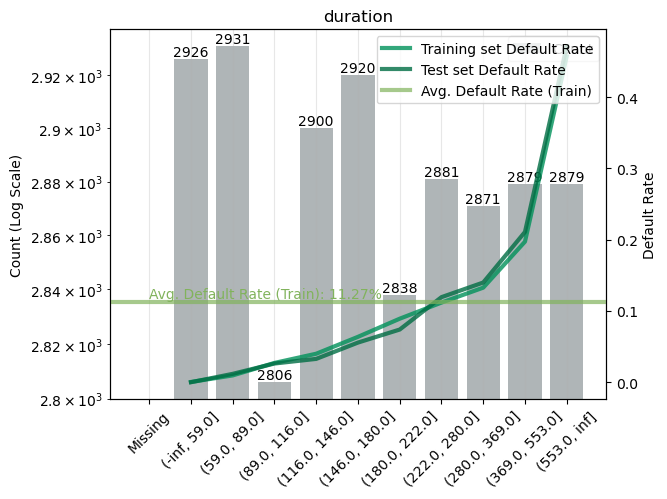

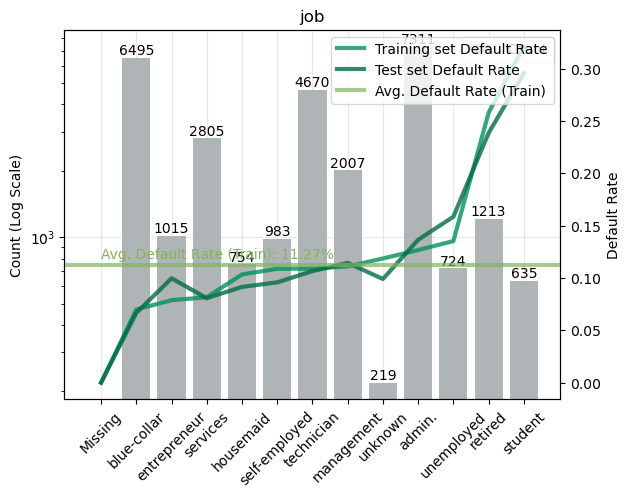

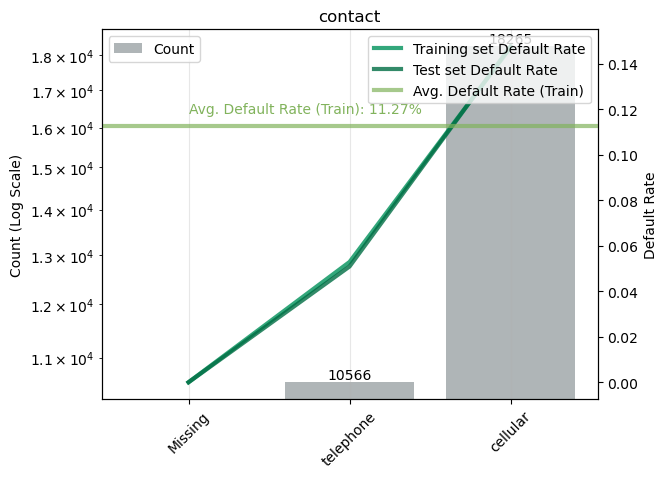

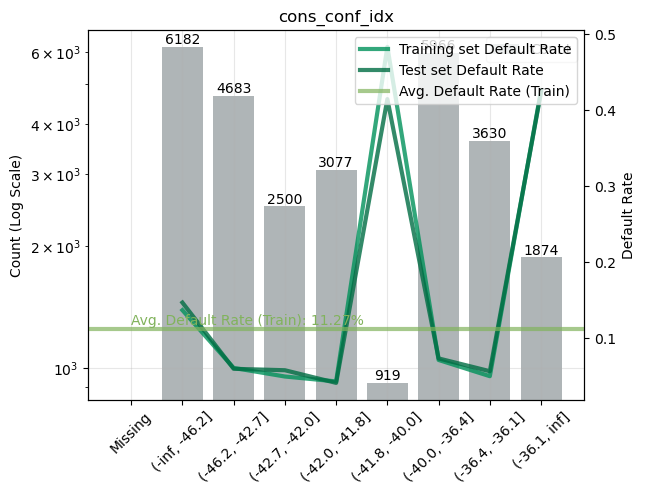

In [15]:
from scoring_tools import classing_plot

for col in ["duration", "job", "contact", "cons_conf_idx"]:
    classing_plot(df_train, df_test, col, target)